# Models: machine M01
One anomaly model per operation, trained on good recordings only, tested on recordings it has never seen. All numbers below come from the code cells.

## Day 4 – train the models and check the anomaly flags
Two models per operation: an RMS threshold as the simple baseline, and the Mahalanobis distance as the main model. Then I check whether they flag the bad recordings and leave the good ones alone.

### Setup
The feature code from notebook 02 now lives in `src/features.py`. This cell computes the 12 features for every window of all 447 recordings, which takes about 20 s.

In [1]:
import sys
sys.path.insert(0, '..')
import datetime, csv
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from src.features import FS, STEP, WIN, NAMES, features, index_recordings, is_idle, load

GOOD, BAD = '#2a78d6', '#eb6834'
idx = index_recordings()
F = {i: features(load(p), op) for i, (p, op) in enumerate(zip(idx['path'], idx['op']))}
print(len(F), 'recordings,', sum(len(v) for v in F.values()), 'windows')

447 recordings, 175980 windows


### Split by recording
Whole recordings go to one part only, never single windows. Neighbouring windows overlap by 75%, so a random window split would put almost the same data in training and test.

- **Bad recordings (34):** all go to test. The models never see bad data, so none is needed for training.
- **Good recordings:** within each operation, shuffled with a fixed seed: 60% train (fit the model), 20% validation (set the threshold), 20% test (count false alarms).

A split by time (train before 2021, test on 2021) would be stricter, but it leaves only 8 bad recordings to test. I use the recording split and report the 2021 bad recordings separately at the end.

In [2]:
rng = np.random.default_rng(0)
idx['split'] = 'test'  # all bad recordings
for op, g in idx[idx['label'] == 'good'].groupby('op'):
    order = rng.permutation(g.index)
    n_train, n_val = round(.6 * len(order)), round(.2 * len(order))
    idx.loc[order[:n_train], 'split'] = 'train'
    idx.loc[order[n_train:n_train + n_val], 'split'] = 'val'
print(idx.groupby(['split', 'label']).size().unstack(fill_value=0))

label  bad  good
split           
test    34    84
train    0   246
val      0    83


### Training data
For each operation, the windows of its train recordings stacked into one table, with idle windows dropped (notebook 02). Each row is one window, each column one of the 12 features.

In [3]:
def stack(rows):
    """Non-idle windows of the given recordings, as one (windows, 12) array."""
    return np.vstack([F[i][~is_idle(F[i])] for i in rows.index])

op = 'OP01'
X = stack(idx[(idx['op'] == op) & (idx['split'] == 'train')])
print(op, 'train windows:', X.shape)

OP01 train windows: (5228, 12)


### Model 1: RMS baseline
The simplest possible detector: the total vibration strength of a window, √(RMS X² + RMS Y² + RMS Z²). It needs no training, only a threshold. If the Mahalanobis model can't beat this, it isn't worth its extra cost on the chip.

In [4]:
def score_rms(model, X):
    return np.sqrt((X[:, :3] ** 2).sum(axis=1))

def fit_rms(X):
    return {}

### Model 2: Mahalanobis distance with Ledoit-Wolf
First each feature is standardized with the training mean and standard deviation, so all 12 features have the same scale. The Mahalanobis distance then measures how far a window lies from the centre of the normal windows, taking into account which features normally move together. A window can be unusual because one feature is extreme, or because features that normally rise together don't.

That needs the covariance matrix (how each pair of features varies together) and its inverse. Estimated from limited data, the covariance gets noisy and its inverse becomes unstable. Ledoit-Wolf fixes this by pulling the estimate a little towards a simple diagonal matrix (shrinkage), and it picks the amount from the data itself.

In [5]:
def fit_maha(X):
    mean, std = X.mean(axis=0), X.std(axis=0)
    lw = LedoitWolf(assume_centered=True).fit((X - mean) / std)
    return dict(mean=mean, std=std, inv=np.linalg.inv(lw.covariance_), shrink=lw.shrinkage_)

def score_maha(m, X):
    Z = (X - m['mean']) / m['std']
    return np.sqrt(np.einsum('ij,jk,ik->i', Z, m['inv'], Z))

m = fit_maha(X)
print(f"{op}: Ledoit-Wolf shrinkage {m['shrink']:.3f}, mean train score {score_maha(m, X).mean():.2f}")

OP01: Ledoit-Wolf shrinkage 0.005, mean train score 2.99


### Fit both models for every operation
Per operation: fit on the train windows, then set the threshold at the 99th percentile of the validation scores. So about 1% of normal windows will go above it. Dividing every score by its operation's threshold puts all operations on one scale: 1 is the threshold.

In [6]:
MODELS = dict(rms=(fit_rms, score_rms), maha=(fit_maha, score_maha))
scores = {name: {} for name in MODELS}   # score / threshold per window, per test recording
val_scores = {name: {} for name in MODELS}
for op, g in idx.groupby('op'):
    for name, (fit, score) in MODELS.items():
        model = fit(stack(g[g['split'] == 'train']))
        threshold = np.percentile(score(model, stack(g[g['split'] == 'val'])), 99)
        for split, out in [('val', val_scores), ('test', scores)]:
            for i in g.index[g['split'] == split]:
                out[name][i] = score(model, F[i][~is_idle(F[i])]) / threshold
test = idx[idx['split'] == 'test']
print(len(scores['maha']), 'test recordings scored:', test['label'].value_counts().to_dict())

118 test recordings scored: {'good': 84, 'bad': 34}


### Window results
How well each window score separates normal from bad windows:
- **AUROC:** the chance that a random bad window scores higher than a random normal one. 0.5 is guessing, 1 is perfect.
- **PR-AUC:** average precision. It accounts for bad windows being rare (6% of test windows here).
- **Recall at 1% FPR:** the share of bad windows caught when only 1% of normal windows may go above the threshold.

In [7]:
def window_metrics(s):
    y = np.concatenate([np.full(len(v), idx.loc[i, 'label'] == 'bad') for i, v in s.items()])
    v = np.concatenate(list(s.values()))
    fpr, tpr, _ = roc_curve(y, v)
    return dict(AUROC=roc_auc_score(y, v), PR_AUC=average_precision_score(y, v), recall=tpr[fpr <= .01].max(),
                normal_above=(v[~y] > 1).mean(), bad_above=(v[y] > 1).mean())

for name in MODELS:
    r = window_metrics(scores[name])
    print(f"{name:5} AUROC {r['AUROC']:.3f}  PR-AUC {r['PR_AUC']:.3f}  recall@1%FPR {r['recall']:.3f}  "
          f"above threshold: normal {r['normal_above']:.2%}, bad {r['bad_above']:.2%}")

rms   AUROC 0.685  PR-AUC 0.501  recall@1%FPR 0.163  above threshold: normal 1.19%, bad 16.67%
maha  AUROC 0.791  PR-AUC 0.600  recall@1%FPR 0.139  above threshold: normal 0.95%, bad 13.68%


### Graph: scores of normal and bad test windows
Score divided by the threshold, so the dashed line at 1 is where a window counts as above threshold. The y axis is a log scale because there are far more normal windows.

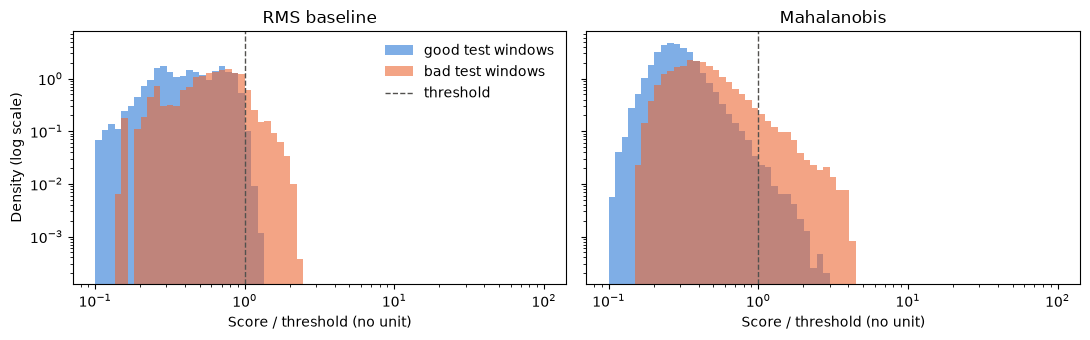

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
bins = np.geomspace(.1, 100, 70)
for ax, name, title in [(axs[0], 'rms', 'RMS baseline'), (axs[1], 'maha', 'Mahalanobis')]:
    for lab, color in [('good', GOOD), ('bad', BAD)]:
        v = np.concatenate([s for i, s in scores[name].items() if idx.loc[i, 'label'] == lab])
        ax.hist(v, bins, color=color, alpha=.6, density=True, label=f'{lab} test windows')
    ax.axvline(1, color='#52514e', ls='--', lw=1, label='threshold')
    ax.set(xscale='log', yscale='log', title=title, xlabel='Score / threshold (no unit)')
axs[0].set_ylabel('Density (log scale)')
axs[0].legend(frameon=False)
fig.tight_layout()
fig.savefig('../results/figures/m01_score_hist.png', dpi=150)
plt.show()

### From windows to flags
The board raises a flag (LED on) only when 3 of the last 5 windows are above the threshold (rule 5), so a single noisy window can't switch the alarm on. The count restarts with each recording, because on the board a new recording means a new operation and model.

A recording counts as flagged when its share of alarm windows is above a limit. I set that limit from the validation recordings only: the largest alarm share any good validation recording reached. So no good validation recording is flagged, and the test set plays no part in the choice.

In [9]:
K, N = 3, 5

def alarms(s):
    """True where at least K of the last N windows are above 1."""
    above = (s > 1).astype(int)
    count = np.convolve(above, np.ones(N, int))[:len(above)]  # windows above among the last N
    return count >= K

print('example:', alarms(np.array([2, 0, 2, 0, 2, 0, 0, 2, 2, 2])).astype(int))
share = {name: {i: alarms(v).mean() for i, v in scores[name].items()} for name in MODELS}
limit = {name: max(alarms(v).mean() for v in val_scores[name].values()) for name in MODELS}
print('recording limit (largest alarm share of a good validation recording):', {k: f'{v:.1%}' for k, v in limit.items()})

example: [0 0 0 0 1 0 0 0 1 1]
recording limit (largest alarm share of a good validation recording): {'rms': '3.7%', 'maha': '2.1%'}


### Recording results
For each model: how many bad test recordings get flagged (caught), and how many good test recordings get flagged (false flags). Detection delay is the time from the start of a bad file to its first alarm. The bad files had their start cut off, so it isn't the time from the start of the fault. False alarms per hour counts how often the alarm switches on during normal test recordings, per hour of normal signal.

In [10]:
rows = []
for name in MODELS:
    flag = {i: share[name][i] > limit[name] for i in test.index}
    bad, good = test.index[test['label'] == 'bad'], test.index[test['label'] == 'good']
    delay = [(np.argmax(alarms(scores[name][i])) * STEP + WIN) / FS for i in bad if alarms(scores[name][i]).any()]
    starts = sum(np.sum(np.diff(alarms(scores[name][i]).astype(int), prepend=0) == 1) for i in good)
    hours = sum(len(scores[name][i]) for i in good) * STEP / FS / 3600
    rows.append(dict(model=name, caught=f'{sum(flag[i] for i in bad)} of {len(bad)}',
                     false_flags=f'{sum(flag[i] for i in good)} of {len(good)}',
                     rec_AUROC=roc_auc_score(test['label'] == 'bad', [share[name][i] for i in test.index]),
                     false_alarms_per_h=starts / hours, median_delay_s=np.median(delay)))
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

model   caught false_flags  rec_AUROC  false_alarms_per_h  median_delay_s
  rms 11 of 34     1 of 84      0.663              28.302           2.432
 maha  8 of 34     2 of 84      0.474              53.275           1.600


### Which bad recordings are missed?
Alarm share of every bad test recording under the Mahalanobis model, lowest first. Anything at or below the limit isn't flagged.

In [11]:
bad = test[test['label'] == 'bad'].copy()
bad['alarm share'] = [share['maha'][i] for i in bad.index]
bad['flagged'] = bad['alarm share'] > limit['maha']
print(bad.sort_values('alarm share')[['op', 'period', 'num', 'alarm share', 'flagged']].head(8).round(3).to_string(index=False))
y21 = bad[bad['period'].str.startswith('2021')]
print(f"\n2021 bad recordings flagged: {y21['flagged'].sum()} of {len(y21)}")

  op  period num  alarm share  flagged
OP01 2019-08 000          0.0    False
OP11 2019-02 000          0.0    False
OP10 2019-02 000          0.0    False
OP10 2021-08 000          0.0    False
OP09 2019-08 000          0.0    False
OP08 2019-02 002          0.0    False
OP08 2019-02 001          0.0    False
OP08 2019-02 000          0.0    False

2021 bad recordings flagged: 5 of 8


### Log to metrics.csv
One row per model and level, so later changes (fewer features, int8, noise) can be compared with this first result.

### Why are so few bad recordings flagged? 1: the threshold
Notebook 02 showed that bad windows stand out clearly, so I look at one operation, OP10, in detail. The cell refits its Mahalanobis model and compares the validation scores of normal windows with the scores of the bad windows.

In [12]:
g = idx[idx['op'] == 'OP10']
m10 = fit_maha(stack(g[g['split'] == 'train']))
val10 = np.concatenate([score_maha(m10, F[i][~is_idle(F[i])]) for i in g.index[g['split'] == 'val']])
print('normal validation windows, score percentiles 50/90/99/99.9:', np.percentile(val10, [50, 90, 99, 99.9]).round(1))
for i in g.index[g['label'] == 'bad']:
    s = score_maha(m10, F[i][~is_idle(F[i])])
    print(f"bad {g.loc[i, 'period']} {g.loc[i, 'num']}: median score {np.median(s):.1f}, windows above threshold {(s > np.percentile(val10, 99)).mean():.0%}")

normal validation windows, score percentiles 50/90/99/99.9: [ 2.7  4.7  9.3 12.9]
bad 2021-08 000: median score 4.8, windows above threshold 0%
bad 2019-02 000: median score 4.7, windows above threshold 3%
bad 2019-02 001: median score 4.4, windows above threshold 4%
bad 2019-02 002: median score 4.4, windows above threshold 4%


### Why are so few bad recordings flagged? 2: normal changes between periods
Median spindle energy of the good recordings of one operation per period, from the training recordings only. If normal moves between periods, one model per operation has to accept all of those levels as normal.

In [13]:
SPIN = [NAMES.index(f'spindle_db {ax}') for ax in 'XYZ']
g = idx[(idx['op'] == 'OP08') & (idx['split'] == 'train')]
per = pd.DataFrame([dict(period=g.loc[i, 'period'], **dict(zip(['X', 'Y', 'Z'], np.median(F[i][~is_idle(F[i])][:, SPIN], axis=0))))
                    for i in g.index])
print('OP08 good train recordings, median spindle energy (dB):')
print(per.groupby('period').median().round(1).to_string())

OP08 good train recordings, median spindle energy (dB):
            X     Y     Z
period                   
2019-02  73.6  88.9  87.6
2019-08  77.8  90.1  87.4
2020-02  84.3  94.8  93.0
2021-02  81.7  88.6  93.9
2021-08  79.0  86.7  93.2


In [14]:
METRICS = '../results/metrics.csv'
FIELDS = ['date', 'source', 'step', 'split', 'level', 'model', 'features', 'quantization', 'SNR', 'AUROC', 'PR_AUC',
          'recall_at_1pct_FPR', 'false_alarms_per_hour', 'detection_delay_s', 'latency_ms']
new = not __import__('os').path.exists(METRICS)
with open(METRICS, 'a', newline='') as f:
    out = csv.DictWriter(f, FIELDS)
    if new:
        out.writeheader()
    for name in MODELS:
        w, r = window_metrics(scores[name]), results.set_index('model').loc[name]
        base = dict(date=datetime.date.today(), source='03_models.ipynb', step='day4 per op, idle dropped, 3 of 5', split='recording',
                    model=name, features=len(NAMES), quantization='float', SNR='', latency_ms='')
        out.writerow({**base, 'level': 'window', 'AUROC': round(w['AUROC'], 4), 'PR_AUC': round(w['PR_AUC'], 4),
                      'recall_at_1pct_FPR': round(w['recall'], 4), 'false_alarms_per_hour': '', 'detection_delay_s': ''})
        out.writerow({**base, 'level': 'recording', 'AUROC': round(r['rec_AUROC'], 4), 'PR_AUC': '', 'recall_at_1pct_FPR': '',
                      'false_alarms_per_hour': round(r['false_alarms_per_h'], 1), 'detection_delay_s': round(r['median_delay_s'], 2)})
print(pd.read_csv(METRICS).to_string())

         date           source                               step      split      level model  features quantization  SNR   AUROC  PR_AUC  recall_at_1pct_FPR  false_alarms_per_hour  detection_delay_s  latency_ms
0  2026-11-13  03_models.ipynb  day4 per op, idle dropped, 3 of 5  recording     window   rms        12        float  NaN  0.6848  0.5015              0.1628                    NaN                NaN         NaN
1  2026-11-13  03_models.ipynb  day4 per op, idle dropped, 3 of 5  recording  recording   rms        12        float  NaN  0.6633     NaN                 NaN                   28.3               2.43         NaN
2  2026-11-13  03_models.ipynb  day4 per op, idle dropped, 3 of 5  recording     window  maha        12        float  NaN  0.7907  0.6001              0.1390                    NaN                NaN         NaN
3  2026-11-13  03_models.ipynb  day4 per op, idle dropped, 3 of 5  recording  recording  maha        12        float  NaN  0.4741     NaN               

### What Day 4 shows
- **The flags aren't good enough yet.** Mahalanobis flags 8 of 34 bad test recordings and 2 of 84 good ones, and the RMS baseline 11 of 34 and 1 of 84. Per window, Mahalanobis is better (AUROC 0.791 against 0.685), but per recording neither model is usable.
- **Cause 1: the threshold is set by rare extreme normal windows.** In OP10, normal windows have a median score of 2.7 and the threshold is 9.3. The bad windows sit at a steady 4.4 to 4.8, clearly above typical normal but almost never above the threshold. The anomaly is steady and moderate, while the threshold guards against short, extreme normal events.
- **Cause 2: normal changes between periods.** OP08's good runs have a median X spindle energy of 73.6 dB in 2019-02 and 84.3 dB in 2020-02, a shift as large as the anomaly. One model per operation trained on all periods must accept the whole range as normal.

Both causes point to the same idea: judge a stretch of windows instead of single windows, and compare against the normal of the current period. Any change is decided from these diagnoses and fixed before the test set is scored again. I have seen the test results once now, so the next test result is no longer fully blind, and I will say so when reporting it.

## Day 5 – period calibration and a 5-second median
Two changes, one for each cause found on Day 4. I fixed all settings below before scoring the test set again. The Day 4 test results were seen once, so this test is no longer fully blind.

### Fix 1: calibrate the centre per period
Each operation keeps one model for the shape of normal (how the features vary and move together), but the centre of normal is set per period from that period's good training recordings. On a real machine this means recording a few good runs after each maintenance or every 6 months.

This needs a new split, done per operation and period: every group keeps at least one good recording for calibration. Groups with n good recordings get max(1, round(0.6 n)) for training, round(0.2 n) for validation and the rest for test, with a fixed seed. All bad recordings go to test. A bad recording from a period without any good recording can't be calibrated, and is listed separately.

In [15]:
rng = np.random.default_rng(0)
idx['split2'] = 'test'
for (op, period), g in idx[idx['label'] == 'good'].groupby(['op', 'period']):
    order = rng.permutation(g.index)
    n_train, n_val = max(1, round(.6 * len(order))), round(.2 * len(order))
    idx.loc[order[:n_train], 'split2'] = 'train'
    idx.loc[order[n_train:n_train + n_val], 'split2'] = 'val'
calibrated = idx.groupby(['op', 'period'])['split2'].transform(lambda s: (s == 'train').any())
print(idx.groupby(['split2', 'label']).size().unstack(fill_value=0))
print('test recordings without calibration:', idx.loc[~calibrated, ['op', 'period', 'label', 'num']].values.tolist())

label   bad  good
split2           
test     34    81
train     0   244
val       0    88
test recordings without calibration: [['OP10', '2021-08', 'bad', '000']]


### Fitting with a centre per period
For each period, the centre is the mean of its training windows. The training windows of all periods, each minus its own period centre, then give the standard deviation and the Ledoit-Wolf covariance of the operation. The RMS baseline gets the same idea: total RMS divided by the median total RMS of the period's training windows.

In [16]:
def fit_op(g):
    """Both models for one operation, with a centre per period."""
    train = g[g['split2'] == 'train']
    centre = {p: stack(t).mean(axis=0) for p, t in train.groupby('period')}
    level = {p: np.median(score_rms({}, stack(t))) for p, t in train.groupby('period')}
    D = np.vstack([stack(t) - centre[p] for p, t in train.groupby('period')])
    std = D.std(axis=0)
    inv = np.linalg.inv(LedoitWolf(assume_centered=True).fit(D / std).covariance_)
    return dict(centre=centre, level=level, std=std, inv=inv)

def score_op(m, name, X, period):
    if name == 'rms':
        return score_rms({}, X) / m['level'][period]
    Z = (X - m['centre'][period]) / m['std']
    return np.sqrt(np.einsum('ij,jk,ik->i', Z, m['inv'], Z))

### Fix 2: judge the median of the last 5 seconds
Day 3 showed the anomaly lasts the whole run, and Day 4 showed normal runs have short extreme moments. The median of the last 40 window scores (40 × 128 ms ≈ 5 s) ignores short spikes but follows a steady rise. There's no alarm until 40 windows have been seen, so detection takes at least about 5.5 s. The example shows a single spike being ignored and a steady rise being followed.

In [17]:
N_MED = 40

def median_score(s):
    """Median of the last N_MED window scores; nan until N_MED windows exist."""
    out = np.full(len(s), np.nan)
    if len(s) >= N_MED:
        out[N_MED - 1:] = np.median(np.lib.stride_tricks.sliding_window_view(s, N_MED), axis=1)
    return out

demo = np.r_[np.ones(50), 100, np.ones(10), np.full(60, 3)]
print('spike only:', np.nanmax(median_score(demo)[:61]), '| after steady rise:', median_score(demo)[-1])

spike only: 1.0 | after steady rise: 3.0


### Fit, threshold and score
Per operation: fit on training recordings, threshold at the 99th percentile of the validation median scores, then score every calibrated test recording. All scores are divided by their threshold, so 1 is the threshold again. The alarm is on wherever the median score is above 1.

In [18]:
med = {name: {} for name in MODELS}
val_med = {name: {} for name in MODELS}
for op, g in idx[calibrated].groupby('op'):
    m = fit_op(g)
    for name in MODELS:
        raw = {i: median_score(score_op(m, name, F[i][~is_idle(F[i])], g.loc[i, 'period'])) for i in g.index if g.loc[i, 'split2'] != 'train'}
        threshold = np.nanpercentile(np.concatenate([raw[i] for i in g.index[g['split2'] == 'val']]), 99)
        for i, v in raw.items():
            (val_med if g.loc[i, 'split2'] == 'val' else med)[name][i] = v / threshold
test2 = idx[calibrated & (idx['split2'] == 'test')]
print(len(med['maha']), 'test recordings scored:', test2['label'].value_counts().to_dict())

114 test recordings scored: {'good': 81, 'bad': 33}


### Results with both fixes
The same measures as on Day 4. Window metrics use only windows that have a median score (40 windows seen). A recording is flagged when its alarm share is above the largest alarm share of any good validation recording.

In [19]:
def results_for(s, val_s, rows, limit=None):
    alarm = {i: np.nan_to_num(v, nan=0) > 1 for i, v in s.items()}
    if limit is None:  # Day 5: largest alarm share of a good validation recording
        limit = max((np.nan_to_num(v, nan=0) > 1).mean() for v in val_s.values())
    share = {i: a.mean() for i, a in alarm.items()}
    bad, good = rows.index[rows['label'] == 'bad'], rows.index[rows['label'] == 'good']
    w = window_metrics({i: v[~np.isnan(v)] for i, v in s.items()})
    starts = sum(np.sum(np.diff(alarm[i].astype(int), prepend=0) == 1) for i in good)
    hours = sum(len(s[i]) for i in good) * STEP / FS / 3600
    delay = [(np.argmax(alarm[i]) * STEP + WIN) / FS for i in bad if alarm[i].any()]
    return dict(caught=sum(share[i] > limit for i in bad), n_bad=len(bad), false_flags=sum(share[i] > limit for i in good), n_good=len(good),
                limit=limit, win_AUROC=w['AUROC'], win_PR_AUC=w['PR_AUC'], recall=w['recall'],
                rec_AUROC=roc_auc_score(rows['label'] == 'bad', [share[i] for i in rows.index]),
                false_alarms_per_h=starts / hours, median_delay_s=np.median(delay), share=share)

res = {name: results_for(med[name], val_med[name], test2) for name in MODELS}
for name, r in res.items():
    print(f"{name:5} caught {r['caught']} of {r['n_bad']}, false flags {r['false_flags']} of {r['n_good']} (limit {r['limit']:.1%}) | "
          f"window AUROC {r['win_AUROC']:.3f} | recording AUROC {r['rec_AUROC']:.3f} | "
          f"false alarms/h {r['false_alarms_per_h']:.1f} | median delay {r['median_delay_s']:.1f} s")

rms   caught 22 of 33, false flags 1 of 81 (limit 6.6%) | window AUROC 0.794 | recording AUROC 0.796 | false alarms/h 31.8 | median delay 5.5 s
maha  caught 24 of 33, false flags 2 of 81 (limit 7.2%) | window AUROC 0.890 | recording AUROC 0.790 | false alarms/h 49.8 | median delay 5.5 s


### Which bad recordings are still missed?
Alarm share of each bad test recording under Mahalanobis, lowest first, and the result for the 2021 bad recordings alone.

In [20]:
bad2 = test2[test2['label'] == 'bad'].copy()
bad2['alarm share'] = [res['maha']['share'][i] for i in bad2.index]
bad2['flagged'] = bad2['alarm share'] > res['maha']['limit']
print(bad2.sort_values('alarm share')[['op', 'period', 'num', 'alarm share', 'flagged']].head(8).round(3).to_string(index=False))
y21 = bad2[bad2['period'].str.startswith('2021')]
print(f"\n2021 bad recordings flagged: {y21['flagged'].sum()} of {len(y21)}")

  op  period num  alarm share  flagged
OP08 2019-02 001          0.0    False
OP12 2019-02 002          0.0    False
OP12 2019-02 001          0.0    False
OP03 2019-08 000          0.0    False
OP12 2019-02 000          0.0    False
OP08 2019-02 000          0.0    False
OP06 2019-08 000          0.0    False
OP09 2019-08 000          0.0    False

2021 bad recordings flagged: 7 of 7


### Why are all three OP12 2019-02 bad recordings missed?
Notebook 01 showed them at +12 dB at the spindle speed, so a 0% alarm share looks like a bug. The cell prints the median 5 s score of every OP12 validation recording and of the three bad ones, before dividing by the threshold.

In [21]:
g = idx[calibrated & (idx['op'] == 'OP12')]
m12 = fit_op(g)
for i in g.index[(g['split2'] == 'val') | (g['label'] == 'bad')]:
    s = median_score(score_op(m12, 'maha', F[i][~is_idle(F[i])], g.loc[i, 'period']))
    print(f"{g.loc[i, 'label']:4} {g.loc[i, 'split2']:4} {g.loc[i, 'period']} {g.loc[i, 'num']}: median {np.nanmedian(s):.1f}")

bad  test 2019-02 000: median 5.5
bad  test 2019-02 001: median 5.3
bad  test 2019-02 002: median 5.0
good val  2019-08 001: median 2.8
good val  2019-08 002: median 2.8
good val  2019-08 006: median 7.4
good val  2019-08 008: median 2.7
good val  2019-02 002: median 2.6
good val  2020-02 000: median 2.7
good val  2021-02 004: median 2.7
good val  2021-02 008: median 2.5


### Graph: score over time
The 5 s median score of four test recordings of OP08, which drifted most between periods: two bad and two good. Above 1 the alarm is on.

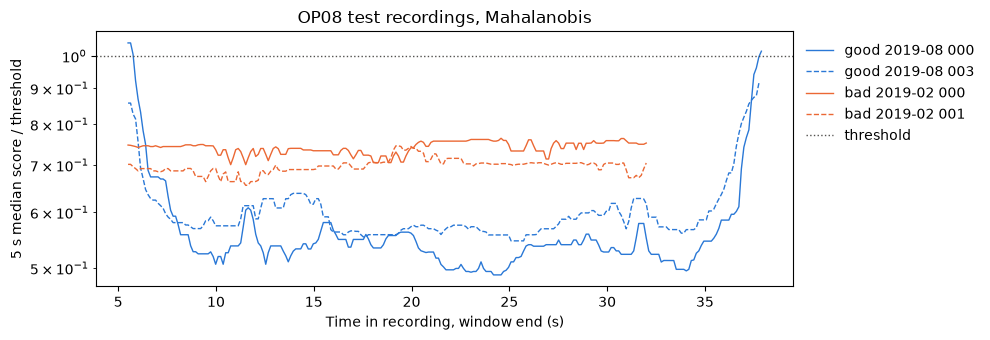

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.5))
show = test2[test2['op'] == 'OP08']
for lab, color in [('good', GOOD), ('bad', BAD)]:
    for n, i in enumerate(show.index[show['label'] == lab][:2]):
        t = (np.arange(len(med['maha'][i])) * STEP + WIN) / FS
        ax.plot(t, med['maha'][i], color=color, lw=1, label=f"{lab} {show.loc[i, 'period']} {show.loc[i, 'num']}", ls='-' if n == 0 else '--')
ax.axhline(1, color='#52514e', ls=':', lw=1, label='threshold')
ax.set(yscale='log', xlabel='Time in recording, window end (s)', ylabel='5 s median score / threshold', title='OP08 test recordings, Mahalanobis')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig('../results/figures/m01_score_over_time.png', dpi=150)
plt.show()

### Log to metrics.csv

In [23]:
with open(METRICS, 'a', newline='') as f:
    out = csv.DictWriter(f, FIELDS)
    for name, r in res.items():
        base = dict(date=datetime.date.today(), source='03_models.ipynb', step='day5 period centre, 5 s median', split='recording by period',
                    model=name, features=len(NAMES), quantization='float', SNR='', latency_ms='')
        out.writerow({**base, 'level': 'window', 'AUROC': round(r['win_AUROC'], 4), 'PR_AUC': round(r['win_PR_AUC'], 4),
                      'recall_at_1pct_FPR': round(r['recall'], 4), 'false_alarms_per_hour': '', 'detection_delay_s': ''})
        out.writerow({**base, 'level': 'recording', 'AUROC': round(r['rec_AUROC'], 4), 'PR_AUC': '', 'recall_at_1pct_FPR': '',
                      'false_alarms_per_hour': round(r['false_alarms_per_h'], 1), 'detection_delay_s': round(r['median_delay_s'], 2)})
print(pd.read_csv(METRICS)[['step', 'level', 'model', 'AUROC', 'false_alarms_per_hour', 'detection_delay_s']].to_string())

                                step      level model   AUROC  false_alarms_per_hour  detection_delay_s
0  day4 per op, idle dropped, 3 of 5     window   rms  0.6848                    NaN                NaN
1  day4 per op, idle dropped, 3 of 5  recording   rms  0.6633                   28.3               2.43
2  day4 per op, idle dropped, 3 of 5     window  maha  0.7907                    NaN                NaN
3  day4 per op, idle dropped, 3 of 5  recording  maha  0.4741                   53.3               1.60
4     day5 period centre, 5 s median     window   rms  0.7944                    NaN                NaN
5     day5 period centre, 5 s median  recording   rms  0.7963                   31.8               5.50
6     day5 period centre, 5 s median     window  maha  0.8898                    NaN                NaN
7     day5 period centre, 5 s median  recording  maha  0.7905                   49.8               5.50


### What Day 5 shows
- **Both fixes help a lot.** Mahalanobis now flags 24 of 33 bad test recordings (Day 4: 8 of 34) with 2 of 81 good ones flagged. Window AUROC rose from 0.791 to 0.890, and all 7 calibrated 2021 bad recordings are flagged. The RMS baseline also improves (22 of 33, 1 false flag) but stays behind Mahalanobis per window (0.794).
- **The price is a slower alarm.** The 5 s median needs 40 windows first, so the median delay is 5.5 s from the start of the file. For a machining operation of 18 to 132 s that is acceptable.
- **One bad recording can't be scored:** OP10 2021-08 has no good recording in its period to calibrate with.
- **OP12 isn't a bug.** Its three bad recordings score 5.0 to 5.5, about twice the 2.5 to 2.8 of the other normal validation runs, but one good validation recording (2019-08 good 006) scores 7.4 and lifts the threshold above them. A single unusual normal run can set the threshold for its whole operation. This shows up in the validation data alone, so a more robust threshold can be chosen without the test set.
- **False alarms are still high:** 49.8 alarm starts per hour of normal signal for Mahalanobis. Most normal recordings never alarm (2 of 81 flagged), so the alarms bunch in a few recordings. In the OP08 plot, the two bad runs stay steadily above the two good runs the whole time, but below the threshold, and the good runs reach the threshold at their start and end, where the machine speeds up and slows down. The model separates them; the threshold sits too high.

This test set was seen once before (Day 4), so these results aren't fully blind.

## Day 6 – a threshold that one recording can't set
Day 5 left two suspects for the missed recordings: one odd normal validation recording lifting the threshold, and normal runs going high at their start and end. I check both on validation recordings only, choose the new rule, and score the test set once at the end.

### Raw 5 s median scores
The same models as Day 5, but the scores are kept before dividing by any threshold, for the validation and test recordings.

In [24]:
raw = {name: {} for name in MODELS}   # 5 s median score, no threshold yet
for op, g in idx[calibrated].groupby('op'):
    m = fit_op(g)
    for name in MODELS:
        for i in g.index[g['split2'] != 'train']:
            raw[name][i] = median_score(score_op(m, name, F[i][~is_idle(F[i])], g.loc[i, 'period']))
val2 = idx[calibrated & (idx['split2'] == 'val')]
print(len(val2), 'validation recordings,', len(raw['maha']) - len(val2), 'test recordings')

88 validation recordings, 114 test recordings


### Check 1: does one recording set the threshold?
Day 5 pooled all validation windows of an operation and took the 99th percentile. Here each validation recording gets its own 99th percentile instead. If the pooled value sits near the highest single recording and far above the typical one, that one recording sets the threshold.

In [25]:
rows = []
for op, g in val2.groupby('op'):
    v = [raw['maha'][i] for i in g.index]
    each = [np.nanpercentile(s, 99) for s in v]
    rows.append(dict(op=op, n_val=len(v), day5_pooled=np.nanpercentile(np.concatenate(v), 99),
                     median_recording=np.median(each), highest_recording=max(each)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

  op  n_val  day5_pooled  median_recording  highest_recording
OP01      8         3.96              3.95               4.21
OP02      9         3.53              3.48               4.51
OP03      6         7.32              4.15               7.70
OP04      6         4.60              4.52               5.49
OP05      7         3.90              3.26               3.95
OP06      4         5.13              5.14               6.16
OP07      9         3.68              3.54               3.79
OP08      7         4.05              3.90               4.60
OP09      7         8.24              4.89               8.75
OP10      7         3.90              3.58               4.33
OP11      4         4.88              4.88               5.26
OP12      8         8.99              3.89              10.30
OP14      6         4.20              3.70               4.48


### New window threshold
Per operation, the median of the validation recordings' own 99th percentiles. Half the normal recordings may then go above it in their top 1% of windows, but one odd recording can't move it much. The same rule is used for the RMS baseline.

In [26]:
thr = {name: {op: np.median([np.nanpercentile(raw[name][i], 99) for i in g.index]) for op, g in val2.groupby('op')}
       for name in MODELS}
print('Mahalanobis threshold per operation:', {op: round(float(t), 2) for op, t in thr['maha'].items()})

Mahalanobis threshold per operation: {'OP01': 3.95, 'OP02': 3.48, 'OP03': 4.15, 'OP04': 4.52, 'OP05': 3.26, 'OP06': 5.14, 'OP07': 3.54, 'OP08': 3.9, 'OP09': 4.89, 'OP10': 3.58, 'OP11': 4.88, 'OP12': 3.89, 'OP14': 3.7}


### Check 2: do normal runs alarm mostly at their start and end?
For every validation window above the new threshold, the distance in seconds to the nearer end of its recording. The first 5.5 s never alarm, because the median needs 40 windows, so a short distance here mostly means the end of a run.

In [27]:
near = []
for i in val2.index:
    a = np.nan_to_num(raw['maha'][i], nan=0) > thr['maha'][idx.loc[i, 'op']]
    t = (np.arange(len(a)) * STEP + WIN) / FS
    near += list(np.minimum(t, t[-1] - t)[a])
near = np.array(near)
print(len(near), 'alarm windows in normal validation recordings')
for sec in [2, 5, 10]:
    print(f'within {sec:2} s of the start or end: {(near <= sec).mean():.0%}')

2110 alarm windows in normal validation recordings
within  2 s of the start or end: 11%
within  5 s of the start or end: 15%
within 10 s of the start or end: 42%


### New recording limit
Day 5 flagged a recording when its alarm share was above the largest share of any good validation recording, so one odd recording set this limit too. Now the limit is the 95th percentile of the alarm shares of all 88 validation recordings: about 1 in 20 normal recordings may be flagged, and the scores are already on one scale (1 = threshold), so the operations can be pooled.

In [28]:
val6 = {name: {i: raw[name][i] / thr[name][idx.loc[i, 'op']] for i in val2.index} for name in MODELS}
limit6 = {}
for name in MODELS:
    shares = np.array([(np.nan_to_num(v, nan=0) > 1).mean() for v in val6[name].values()])
    limit6[name] = np.percentile(shares, 95)
    print(f"{name:5} largest validation share {shares.max():.1%} (Day 5 rule) -> 95th percentile {limit6[name]:.1%}, "
          f"validation recordings flagged {(shares > limit6[name]).sum()} of {len(shares)}")

rms   largest validation share 86.4% (Day 5 rule) -> 95th percentile 53.2%, validation recordings flagged 5 of 88
maha  largest validation share 94.3% (Day 5 rule) -> 95th percentile 35.2%, validation recordings flagged 5 of 88


### Test results with the new threshold and limit
All choices above used validation recordings only. The test set is now scored once with them, using the same measures as Day 5.

In [29]:
med6 = {name: {i: raw[name][i] / thr[name][idx.loc[i, 'op']] for i in test2.index} for name in MODELS}
res6 = {name: results_for(med6[name], val6[name], test2, limit6[name]) for name in MODELS}
for name, r in res6.items():
    print(f"{name:5} caught {r['caught']} of {r['n_bad']}, false flags {r['false_flags']} of {r['n_good']} (limit {r['limit']:.1%}) | "
          f"window AUROC {r['win_AUROC']:.3f} | recording AUROC {r['rec_AUROC']:.3f} | "
          f"false alarms/h {r['false_alarms_per_h']:.1f} | median delay {r['median_delay_s']:.1f} s")

rms   caught 27 of 33, false flags 2 of 81 (limit 53.2%) | window AUROC 0.857 | recording AUROC 0.865 | false alarms/h 186.2 | median delay 5.5 s


maha  caught 28 of 33, false flags 3 of 81 (limit 35.2%) | window AUROC 0.936 | recording AUROC 0.852 | false alarms/h 93.5 | median delay 5.5 s


### Which bad recordings are still missed?

In [30]:
bad6 = test2[test2['label'] == 'bad'].copy()
bad6['alarm share'] = [res6['maha']['share'][i] for i in bad6.index]
bad6['flagged'] = bad6['alarm share'] > res6['maha']['limit']
print(bad6[~bad6['flagged']].sort_values('alarm share')[['op', 'period', 'num', 'alarm share']].round(3).to_string(index=False))
y21 = bad6[bad6['period'].str.startswith('2021')]
print(f"\n2021 bad recordings flagged: {y21['flagged'].sum()} of {len(y21)}")

  op  period num  alarm share
OP06 2019-08 000          0.0
OP08 2019-02 000          0.0
OP08 2019-02 001          0.0
OP08 2019-02 002          0.0
OP09 2019-08 000          0.0

2021 bad recordings flagged: 7 of 7


### Log to metrics.csv

In [31]:
with open(METRICS, 'a', newline='') as f:
    out = csv.DictWriter(f, FIELDS)
    for name, r in res6.items():
        base = dict(date=datetime.date.today(), source='03_models.ipynb', step='day6 median-of-recordings threshold, 95% limit',
                    split='recording by period', model=name, features=len(NAMES), quantization='float', SNR='', latency_ms='')
        out.writerow({**base, 'level': 'window', 'AUROC': round(r['win_AUROC'], 4), 'PR_AUC': round(r['win_PR_AUC'], 4),
                      'recall_at_1pct_FPR': round(r['recall'], 4), 'false_alarms_per_hour': '', 'detection_delay_s': ''})
        out.writerow({**base, 'level': 'recording', 'AUROC': round(r['rec_AUROC'], 4), 'PR_AUC': '', 'recall_at_1pct_FPR': '',
                      'false_alarms_per_hour': round(r['false_alarms_per_h'], 1), 'detection_delay_s': round(r['median_delay_s'], 2)})
print(pd.read_csv(METRICS)[['step', 'level', 'model', 'AUROC', 'false_alarms_per_hour', 'detection_delay_s']].to_string())

                                              step      level model   AUROC  false_alarms_per_hour  detection_delay_s
0                day4 per op, idle dropped, 3 of 5     window   rms  0.6848                    NaN                NaN
1                day4 per op, idle dropped, 3 of 5  recording   rms  0.6633                   28.3               2.43
2                day4 per op, idle dropped, 3 of 5     window  maha  0.7907                    NaN                NaN
3                day4 per op, idle dropped, 3 of 5  recording  maha  0.4741                   53.3               1.60
4                   day5 period centre, 5 s median     window   rms  0.7944                    NaN                NaN
5                   day5 period centre, 5 s median  recording   rms  0.7963                   31.8               5.50
6                   day5 period centre, 5 s median     window  maha  0.8898                    NaN                NaN
7                   day5 period centre, 5 s median  reco

### What Day 6 shows
- **One recording did set the threshold.** In OP12 the pooled Day 5 threshold was 8.99, while the typical validation recording has its 99th percentile at 3.89. One good recording (10.30) set it. OP03 and OP09 show the same. The median over recordings ignores such a run.
- **Start and end of a run are not the main cause.** Only 15% of normal alarm windows are within 5 s of the end of a run, so cutting the start and end wouldn't help much. The board also can't know when a run is about to end, so I dropped that idea.
- **More bad recordings are caught.** Mahalanobis now flags 28 of 33 bad test recordings (Day 5: 24) and 3 of 81 good ones (Day 5: 2). All three OP12 bad recordings are caught now. Window AUROC rose from 0.890 to 0.936, because the scores of different operations are now on a fairer common scale. The RMS baseline catches 27 of 33 but reaches only 0.857 per window.
- **The price is a lower threshold.** False alarm starts per hour of normal signal doubled, from 49.8 to 93.5. A recording only counts as flagged when the alarm is on for more than 35% of it, so on the board the LED would also blink briefly during normal runs. That needs a rule for the LED, not only for the recording.
- **Still missed:** OP08 2019-02 (all three bad recordings), OP06 2019-08 and OP09 2019-08. OP09 already looked normal in notebook 01. Their alarm share is 0, so they never cross the threshold.

The test set was scored once with rules chosen on validation data, but it had been seen on Days 4 and 5, so this result isn't fully blind either.